In [1]:
import scanpy as sc
import pandas as pd
import squidpy as sq
import seaborn as sns
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap



/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: 

In [2]:
key_celltype = "broad_celltypes"
sc.settings.set_figure_params(dpi_save=300, facecolor="white", frameon=False, figsize=(15, 15))


In [3]:
DATA_PREPARED=True
DATA_PREPARED_T=True


In [4]:
# #adata=sc.read_h5ad('/nfs/team361/ls34/inflow/adata_10ad_spatial_validation2.h5ad')

# RECODE = {'original': 'revision',
#           'revision': 'original'


# }
# adata.obs["Mapping status"]=adata.obs["Mapping status"].map(RECODE)
# adata.obs["Mapping status"].value_counts()

In [5]:
# adata.obs["Mapping status"].isna().sum()

In [6]:
# adata.write('/nfs/team361/ls34/inflow/adata_10ad_spatial_validation2.h5ad')


In [7]:
if DATA_PREPARED:
    adata=sc.read_h5ad('/nfs/team361/ls34/inflow/adata_10ad_spatial_validation2.h5ad')
else:
   #adata=sc.read_h5ad('/nfs/team361/ls34/adata_mm_spatial_prepped.h5ad')
    RUNID=1
    PATH = f'/nfs/team361/aa36/OnGit/mintflow-benchmarking/AK_Private/14_ADandnewAD_4Lloyd/NonGit/Run_Outputs/March8th_ADandnewAD_Run{RUNID}/adata_epoch_19.h5ad'
    adata=sc.read_h5ad(PATH)
    adata

try:
    adata.obs["NICHE_NAMES"] = adata.obs["niche_name"]
except:
    adata
    
adata  

AnnData object with n_obs × n_vars = 400880 × 5001
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'sample_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'Patient_status', 'xenium_id', 'xenium_id_recoded', 'info_id6', 'sample_id_original', 'sample_id2', 'timepoint', 'drug', 'responder', 'new_annotation', '6m_easi', 'baseline_easi', 'response', 'tmp', 'broad_annotation', 'Sanger patient ID', 'Drug', 'Responder', 'Timepoint', 'Site_status', 'info_id', 'sample', 'niche_name', 'lvl1', 'lvl0', 'veryfine_celltypes_new5', 'veryfine_celltypes_new5_incprolif', 'veryfine_celltypes', 'fine_celltypes_

In [8]:
adata.obs["Sanger patient ID"].value_counts()

Sanger patient ID
BK30    48239
BK23    43869
BK39    33841
BK22    21656
BK18    17792
BK27    16555
BK21    15531
Name: count, dtype: int64

In [9]:
2

2

In [10]:
{x:x for x in adata[adata.obs["Sanger patient ID"].isna()].obs.sample_id.unique()}

{'BK44-SKI-27-FO-1-S4-E2': 'BK44-SKI-27-FO-1-S4-E2',
 'BK36-SKI-27-FO-1-S5-E1': 'BK36-SKI-27-FO-1-S5-E1',
 'BK37-SKI-27-FO-1-S4-C1': 'BK37-SKI-27-FO-1-S4-C1',
 'BK58-SKI-27-FO-1-S5-A1': 'BK58-SKI-27-FO-1-S5-A1',
 'BK36-SKI-27-FO-1-S4-D1': 'BK36-SKI-27-FO-1-S4-D1',
 'BK68-SKI-27-FO-1-S4-B2': 'BK68-SKI-27-FO-1-S4-B2',
 'BK65-SKI-21-FO-1-S4-B1': 'BK65-SKI-21-FO-1-S4-B1',
 'BK42-SKI-27-FO-1-S4-C2': 'BK42-SKI-27-FO-1-S4-C2',
 'BK40-SKI-27-FO-1-S4-D2': 'BK40-SKI-27-FO-1-S4-D2',
 'BK58-SKI-27-FO-4-S4-A2': 'BK58-SKI-27-FO-4-S4-A2'}

In [11]:
RENAME = {'BK44-SKI-27-FO-1-S4-E2': 'BK44',
 'BK36-SKI-27-FO-1-S5-E1': 'BK36',
 'BK37-SKI-27-FO-1-S4-C1': 'BK37',
 'BK58-SKI-27-FO-1-S5-A1': 'BK58',
 'BK36-SKI-27-FO-1-S4-D1': 'BK36',
 'BK68-SKI-27-FO-1-S4-B2': 'BK68',
 'BK65-SKI-21-FO-1-S4-B1': 'BK65',
 'BK42-SKI-27-FO-1-S4-C2': 'BK42',
 'BK40-SKI-27-FO-1-S4-D2': 'BK40',
 'BK58-SKI-27-FO-4-S4-A2': 'BK58'}
adata.obs["Sanger patient ID"]=adata.obs["sample_id"].map(RENAME).fillna(adata.obs["Sanger patient ID"])
adata.obs["Sanger patient ID"].value_counts()

Sanger patient ID
BK30    48239
BK23    43869
BK36    38094
BK39    33841
BK44    30151
BK40    29527
BK58    27201
BK68    24602
BK22    21656
BK65    19762
BK42    19273
BK18    17792
BK27    16555
BK21    15531
BK37    14787
Name: count, dtype: int64

In [12]:
adata.obs["Sanger patient ID"].nunique()

15

In [13]:
adata.obs["Sanger patient ID"].isna().sum()

0

In [14]:
adata.obs['spatial_niche'].value_counts()

spatial_niche
Epidermis_mid      69720
Stroma             28664
Neuromuscular      19319
Mac_T_cDC2         18958
Perivascular       13255
T_DC               11527
Epidermis_basal    11172
Blood vessel       10906
Epidermis_late      8255
Sweat gland         5707
Name: count, dtype: int64

In [15]:
adata.obs['Mapping status'].value_counts()

Mapping status
revision    203397
original    197483
Name: count, dtype: int64

In [16]:
adata.obs.sample_id.value_counts()

sample_id
output-XETG00155__0043607__BK30-SKI-28-FO-1-S3-4__20241010__133127                            30861
BK44-SKI-27-FO-1-S4-E2                                                                        30151
BK40-SKI-27-FO-1-S4-D2                                                                        29527
output-XETG00272__0041416__BK23-SKI-27-FO-1-S6-C2__20241107__113553                           25625
BK68-SKI-27-FO-1-S4-B2                                                                        24602
output-XETG00272__0041416__BK22-SKI-27-FO-1-S10-A1__20241107__113553                          21656
BK65-SKI-21-FO-1-S4-B1                                                                        19762
BK36-SKI-27-FO-1-S4-D1                                                                        19285
BK42-SKI-27-FO-1-S4-C2                                                                        19273
BK36-SKI-27-FO-1-S5-E1                                                                    

In [18]:
# sc.pl.umap(adata,  
#                color=[ "spatial_niche"],
#                s=20,
#                legend_loc="on data",
#                legend_fontsize=18)


In [19]:
M_BAR_METRIC = "MintFlow_Xbar_mic"

In [20]:
DATA_PREPARED

True

In [21]:
if not DATA_PREPARED:

    sc.pp.neighbors(adata, use_rep = M_BAR_METRIC, 
                    metric = "euclidean", n_neighbors=20)#key_added=neighbor_id)
    sc.tl.umap(adata, min_dist=0.1) #neighbor_key=)


    sc.pl.umap(adata,  
               color=[ "NICHE_NAMES", key_celltype],
               s=20,legend_loc="on data",
               legend_fontsize=8)

    RES=0.1

    sc.pl.umap(adata,  
               color=[ key_celltype,] ,
               s=20,legend_loc="on data",
               legend_fontsize=8
              )
    sc.tl.leiden(adata, #restrict_to=(CATEGORY,subset_cluster), 
                 resolution=RES, random_state=1, key_added=f'leiden_res{RES}') #neighbors_key='neighbor_30')




    # for x in adata.obs["info_id"].unique():
    #     adata_ii=adata_i[adata_i.obs["info_id"]==x]
    #     adata_iii=adata[adata.obs["info_id"]==x]

    #     sq.pl.spatial_scatter(
    #             adata_ii,
    #             library_id="spatial",
    #             shape=None,
    #             color=f'leiden_res{RES}',
    #             size=100,
    #             title=''
    #         )

    #     # try:
    #     #     adata_i.uns.pop('niche_colors')
    #     # except:
    #     #     1
    #     sq.pl.spatial_scatter(
    #             adata_iii,
    #             library_id="spatial",
    #             shape=None,
    #             color=f'NICHE_NAMES',
    #             size=10,
    #             title=''
    #         )
# sc.pl.dotplot(adata_i, 
#               remove_markers(ALL_T),
#               groupby=f'leiden_res{RES}',
#               dendrogram=False, 
#                 standard_scale="var",
#              dot_max=0.3,)

else:
    print("skip as data prepared")

skip as data prepared


In [22]:
# sc.settings.set_figure_params(dpi=50, facecolor="white", frameon=False, figsize=(5, 5))


# n_batches = adata.obs["info_id"].nunique()
# color_palette = sns.color_palette("tab20", n_colors=n_batches)

# info_id_colors = {
#     str(i): mcolors.to_hex(c) for i, c in enumerate(color_palette)
# }

# adata.uns["info_id_colors"] = list(info_id_colors.values())

# adata.obs["info_id"] = (
#     adata.obs["info_id"]
#         .astype("category")
#         .cat.codes
#         .astype(str)
# )


# ax = sc.pl.umap(
#     adata,
#     color=["info_id"],
#     s=1,
#     legend_fontsize=8,
#     show=False,
#     title="",
# )


# handles, labels = ax.get_legend_handles_labels()
# ax.legend(
#     handles, labels,
#     fontsize=8,
#     ncol=4,
#     bbox_to_anchor=(1, 1),
#     loc="upper left",
#     frameon=False,
#     scatterpoints=3,
#     title="",
# )

# plt.tight_layout()
# #plt.savefig("figures/batch_extrinsic.pdf", bbox_inches="tight", dpi=3000)
# plt.show()

# sc.settings.set_figure_params(dpi=50, facecolor="white", frameon=False, figsize=(12, 12))


In [23]:
# RES=0.5
# if not DATA_PREPARED:
#     sc.pl.umap(adata,  
#                color=[f'leiden_res{RES}', "NICHE_NAMES"],
#                s=20,
#                legend_loc="on data",
#                legend_fontsize=18)


In [24]:
if not DATA_PREPARED:
    RENAME = {'0': "Epidermis_mid",
     '1': "Neuromuscular",
     '2': "Epidermis_mid",# "Epidermis_basal",
     '3': "Mac_T_cDC2",# "Large blood vessel+muscle",
     '4': "Stroma",
     '5':  "Epidermis_mid",# "Stroma",
     '6': "Epidermis_mid", #"Mac_rich",
     '7':  "Perivascular", #"Stroma_deep",
     '8': "Stroma", #"Epidermis inflamm",
     '9':  "T_DC",# "T_cDC rich",
     '10':  "Epidermis_basal", # "Small lood vessel",
     '11': "Epidermis_late", #"n mid",
     '12':  "Blood vessel",
              "13": "Sweat gland",
              "14":  "Blood vessel",
             }
    adata.obs["spatial_niche"] = adata.obs[f'leiden_res{RES}'].map(RENAME)
    sc.pl.umap(adata,  
           color=[f'spatial_niche', "NICHE_NAMES"],
           s=20,
           legend_loc="on data",
           legend_fontsize=18,
          legend_fontoutline=2)



In [25]:
adata

AnnData object with n_obs × n_vars = 400880 × 5001
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'sample_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'Patient_status', 'xenium_id', 'xenium_id_recoded', 'info_id6', 'sample_id_original', 'sample_id2', 'timepoint', 'drug', 'responder', 'new_annotation', '6m_easi', 'baseline_easi', 'response', 'tmp', 'broad_annotation', 'Sanger patient ID', 'Drug', 'Responder', 'Timepoint', 'Site_status', 'info_id', 'sample', 'niche_name', 'lvl1', 'lvl0', 'veryfine_celltypes_new5', 'veryfine_celltypes_new5_incprolif', 'veryfine_celltypes', 'fine_celltypes_

# extended 10a

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


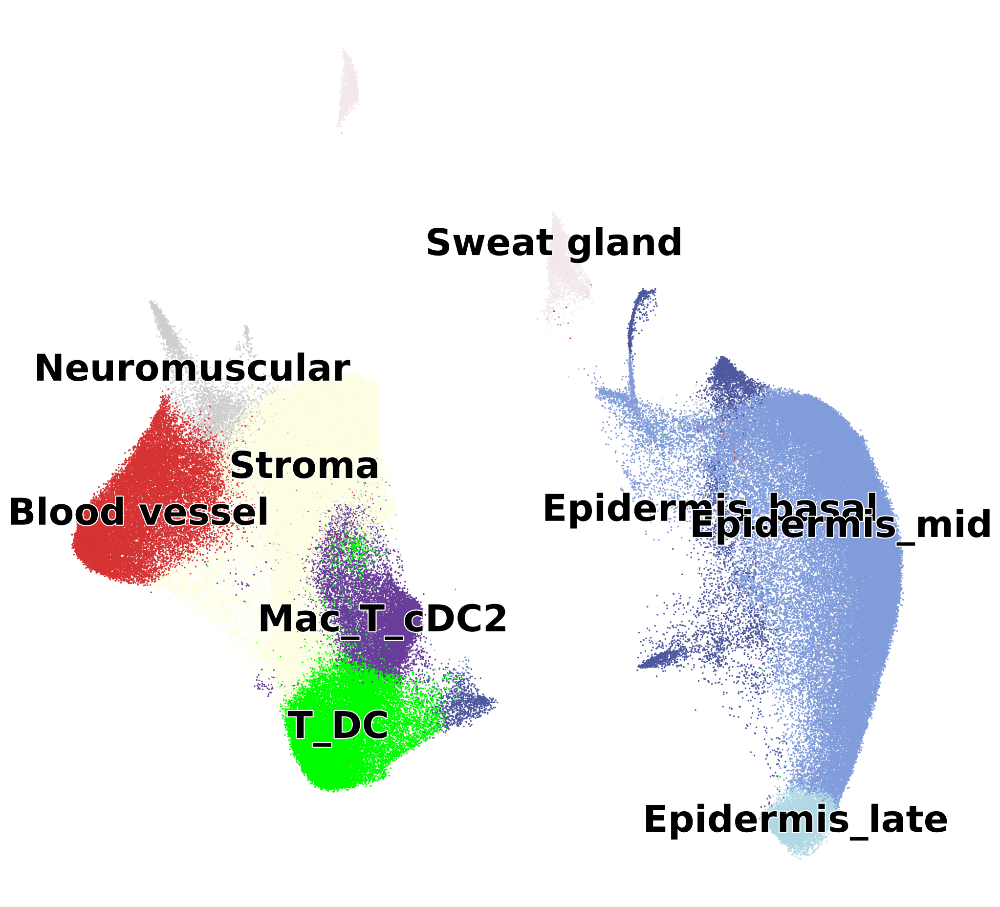

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


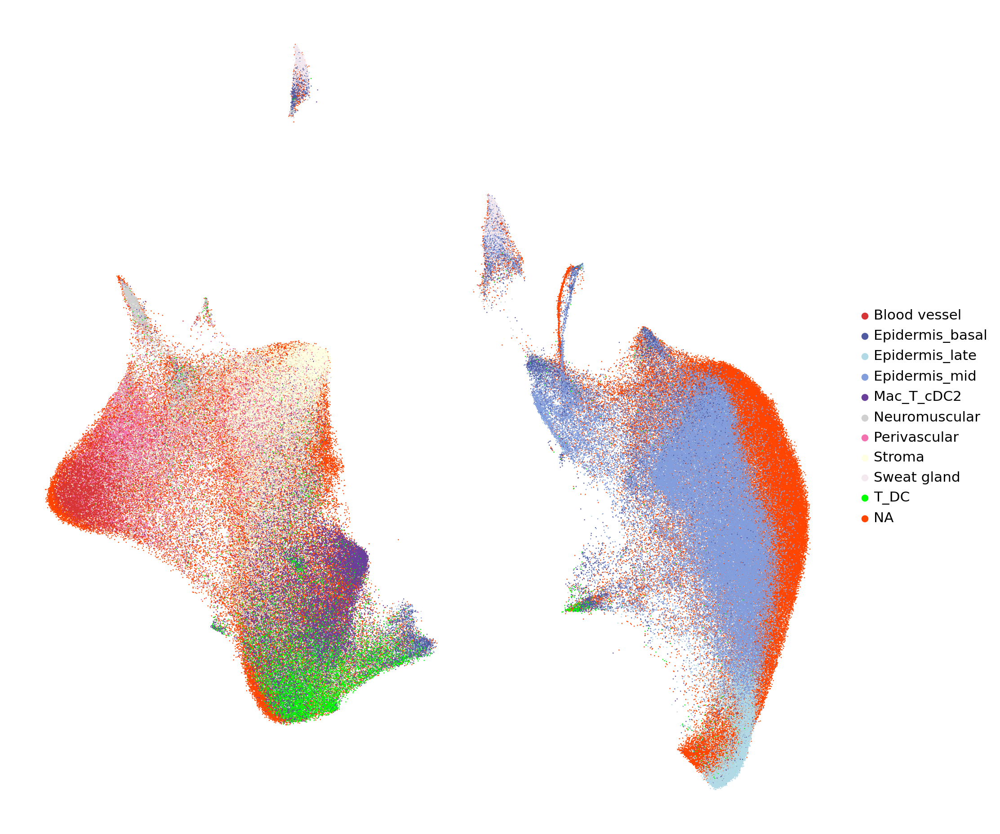

In [26]:
COLORS = {'Mac_T_cDC2': '#6A3F9B',
          'Neuromuscular': '#D0D0D0',
# 'Stroma_deep': "#f6d17a", 
 'T_rich': "#dcb0f2",#'#F4D1A1',
 'Blood vessel': '#d73435',
 'T_DC': '#00FF00',
 'Appendage': "#e28743", #'#94cb72',
 'Sweat gland': '#839edd',
 'Epidermis_late': '#b1dae6',
 'Perivascular': '#f371af',
 'Stroma':'#FFFFE4', # '#f6d17a',
 'Epidermis_mid': '#839edd',
 'Sweat gland': '#f4e9ef',
 'Epidermis_basal': '#505aa1'}
colors=COLORS


adata.obs['spatial_niche2']=adata.obs['spatial_niche2'].astype('category')
adata.uns['spatial_niche2_colors'] = [COLORS[cat] for cat in adata.obs['spatial_niche2'].cat.categories]


# sc.pl.umap(
#     adata,
#     color=['spatial_niche2'],
#     s=40,
# legend_loc="on data",
#     legend_fontsize=14,
#     legend_fontoutline=2,
#     title="",
#     linewidth=0.1,
#             edgecolor="black",

# )

# # sc.pl.umap(
#     adata,
#     color=['spatial_niche'],
#     s=20,
# legend_loc=None,
#     legend_fontsize=14,
#     legend_fontoutline=2,
#     title="",
#     linewidth=0.1,
#             edgecolor="lightgrey",
#         save="extrinsic_umap_nolabels.pdf"

#    # alpha=0.6

# )

sc.pl.umap(
    adata[adata.obs["Mapping status"]=="revision"],
    color=['spatial_niche2'],
    na_color='#FF4500',  # neon orange-red for NaN values
    s=10,
    legend_loc="on data",
    legend_fontsize=34,
    legend_fontoutline=2,
    title="",
    linewidth=0.001,
    edgecolor="black",
        save="validation_umap_relabelled.pdf"

)
sc.pl.umap(
    adata,
    color=['spatial_niche'],
    na_color='#FF4500',  # neon orange-red for NaN values
    s=5,
   # legend_loc="on data",
    legend_fontsize=14,
    legend_fontoutline=2,
    title="",
    save="validation_umap.pdf"
    #linewidth=0.001,
    #edgecolor="black",
)

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


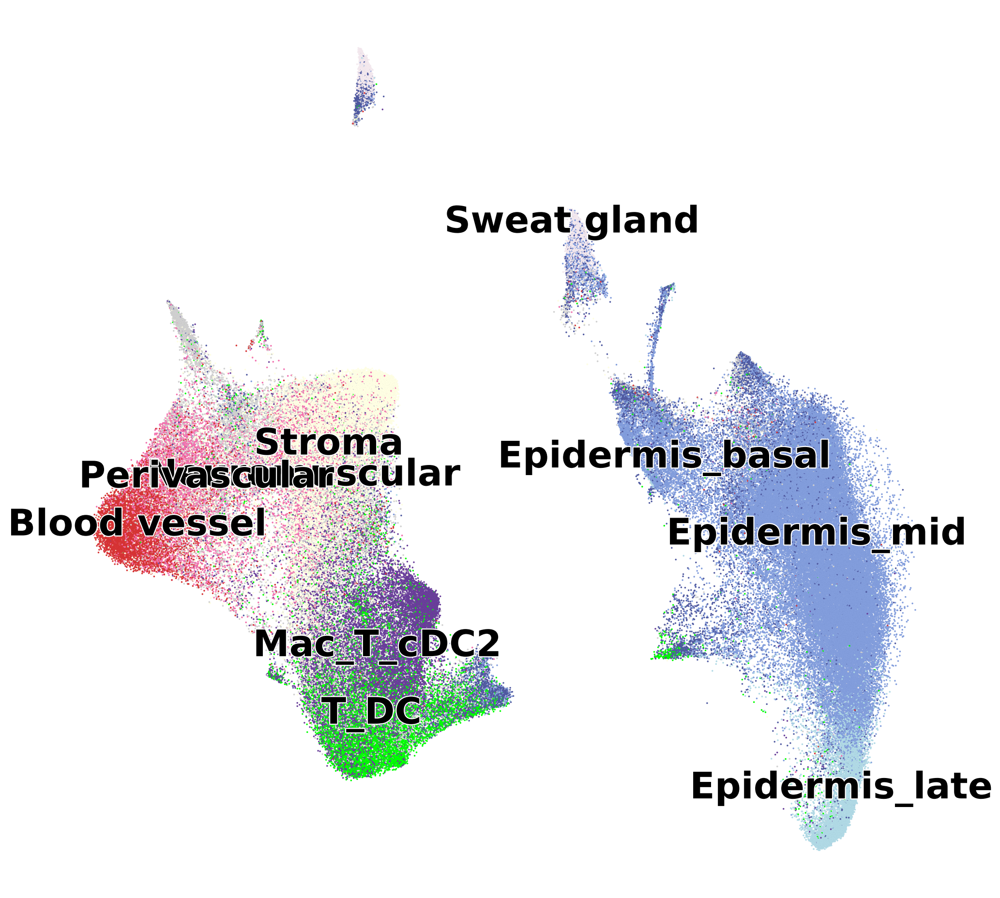

In [27]:

sc.pl.umap(
    adata[adata.obs["Mapping status"]=="original"],
    color=['spatial_niche'],
    na_color='#FF4500',  # neon orange-red for NaN values
    s=10,
    legend_loc="on data",
    legend_fontsize=34,
    legend_fontoutline=2,
    title="",
    linewidth=0.001,
    edgecolor="black",
        save="validation_umap_originaldataonly.pdf"

)

In [28]:
adata

AnnData object with n_obs × n_vars = 400880 × 5001
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'sample_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'Patient_status', 'xenium_id', 'xenium_id_recoded', 'info_id6', 'sample_id_original', 'sample_id2', 'timepoint', 'drug', 'responder', 'new_annotation', '6m_easi', 'baseline_easi', 'response', 'tmp', 'broad_annotation', 'Sanger patient ID', 'Drug', 'Responder', 'Timepoint', 'Site_status', 'info_id', 'sample', 'niche_name', 'lvl1', 'lvl0', 'veryfine_celltypes_new5', 'veryfine_celltypes_new5_incprolif', 'veryfine_celltypes', 'fine_celltypes_

BK40-SKI-27-FO-1-S4-D2


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


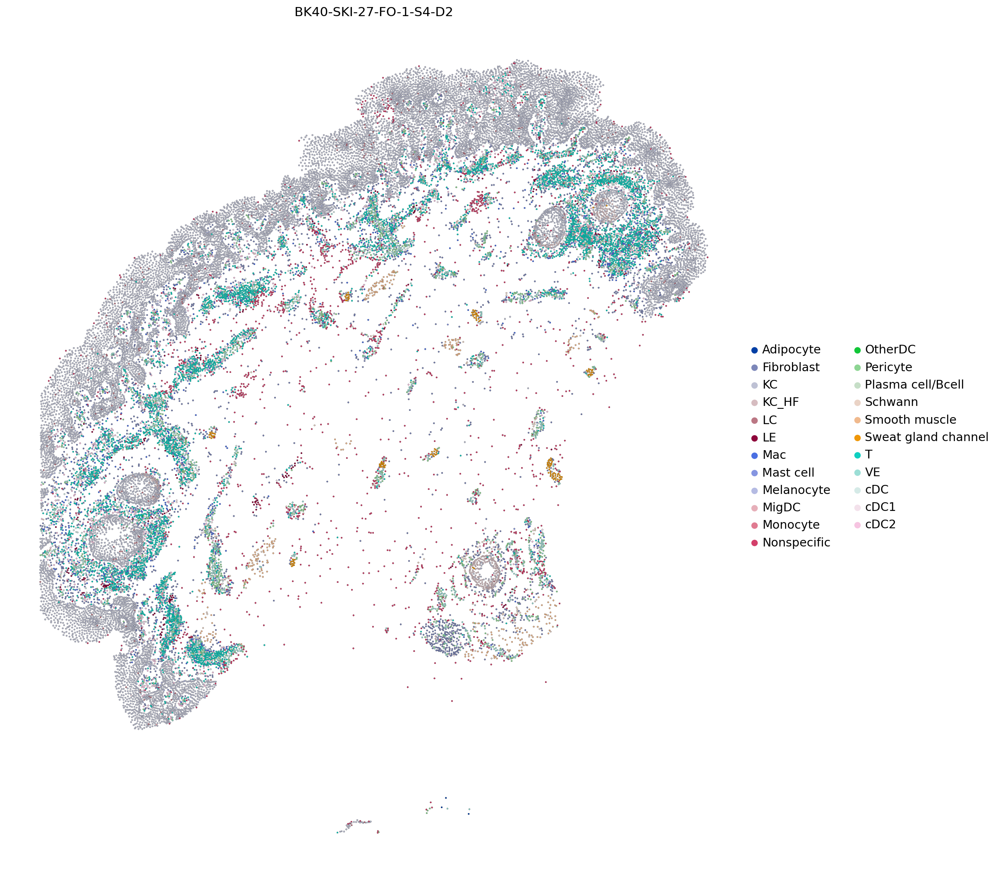

In [29]:

# # COLOR = {
# #     'Dermis': '#D8C59A',
# #     'Superficial': '#F87A7B'
# # }
# # color_palette = ListedColormap([COLOR[k] for k in COLOR.keys()])
# for x in adata[adata.obs["Mapping status"]=="revision"].obs["sample_id"].unique():
#     if "BK40" in x:
#         adata_ii = adata[adata.obs["sample_id"] == x]
#         #if x == "BK22":
#         print(x)
#         sq.pl.spatial_scatter(
#             adata_ii,
#             library_id="spatial",
#             shape=None,
#             color='broad_annotations',  
#             size=10,
#             edgecolor="black",
#             linewidth=0.1,
#             title=x,
#             vmax=5,
#           #  cmap="Reds",
#             save=f"{x}_CD8_UMAP_ALLCELLS.pdf"
#                # save = "umap_tcells_spatialdomain_forhande.pdf"

#             #palette=color_palette  
#         )

BK58-SKI-27-FO-1-S5-A1


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


BK58-SKI-27-FO-4-S4-A2


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


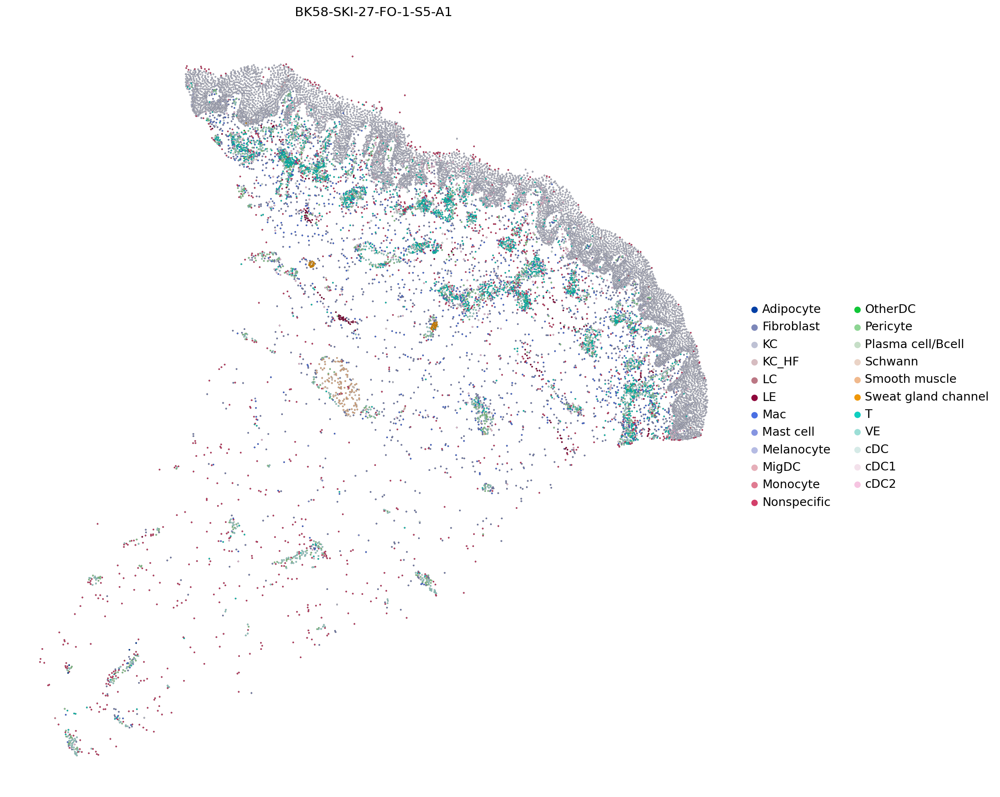

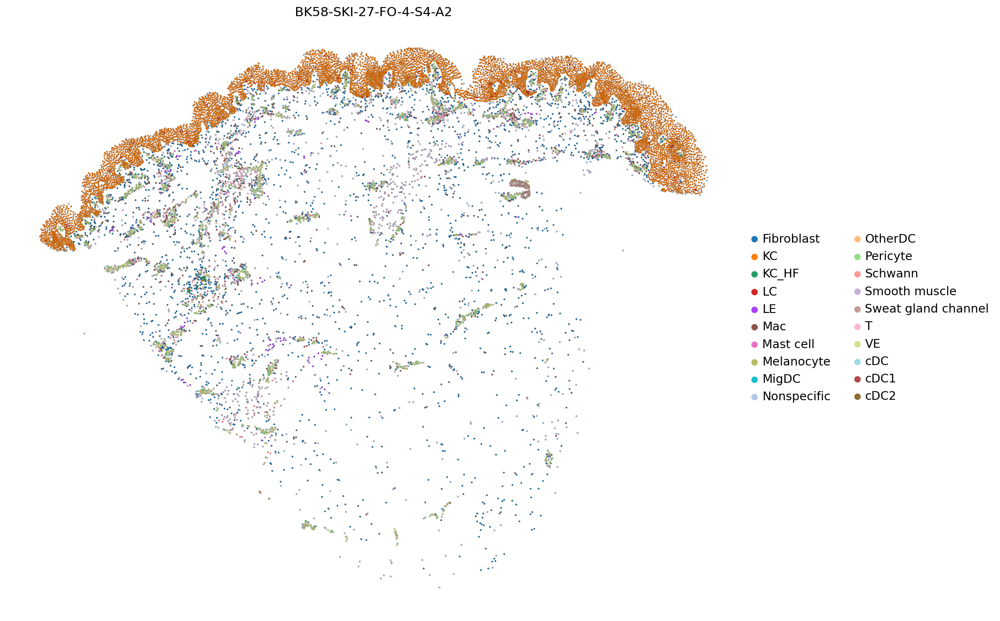

In [30]:

# # COLOR = {
# #     'Dermis': '#D8C59A',
# #     'Superficial': '#F87A7B'
# # }
# # color_palette = ListedColormap([COLOR[k] for k in COLOR.keys()])
# for x in adata[adata.obs["Mapping status"]=="revision"].obs["sample_id"].unique():
#     if "BK58" in x:
#         adata_ii = adata[adata.obs["sample_id"] == x]
#         #if x == "BK22":
#         print(x)
#         sq.pl.spatial_scatter(
#             adata_ii,
#             library_id="spatial",
#             shape=None,
#             color='broad_annotations',  
#             size=10,
#             edgecolor="black",
#             linewidth=0.1,
#             title=x,
#             vmax=5,
#           #  cmap="Reds",
#             save=f"{x}_CD8_UMAP_ALLCELLS.pdf"
#                # save = "umap_tcells_spatialdomain_forhande.pdf"

#             #palette=color_palette  
#         )

BK58-SKI-27-FO-1-S5-A1
BK58-SKI-27-FO-4-S4-A2


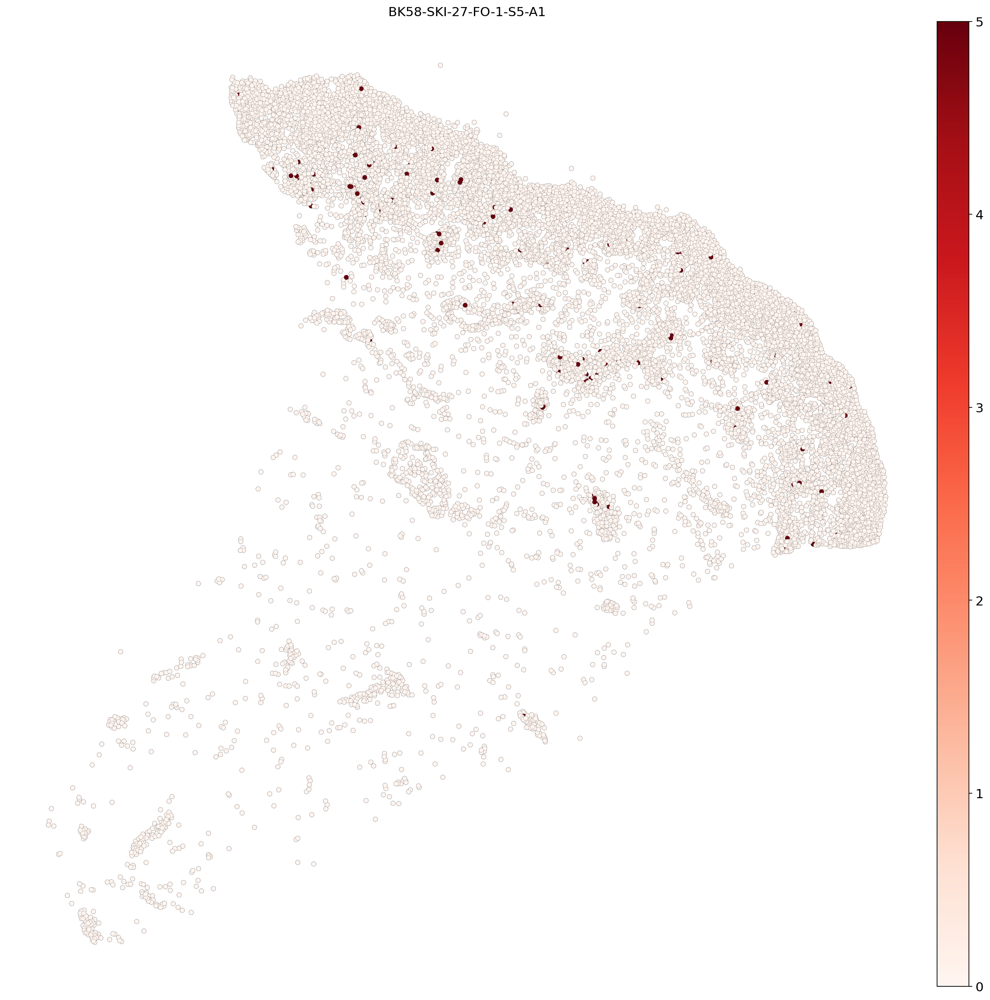

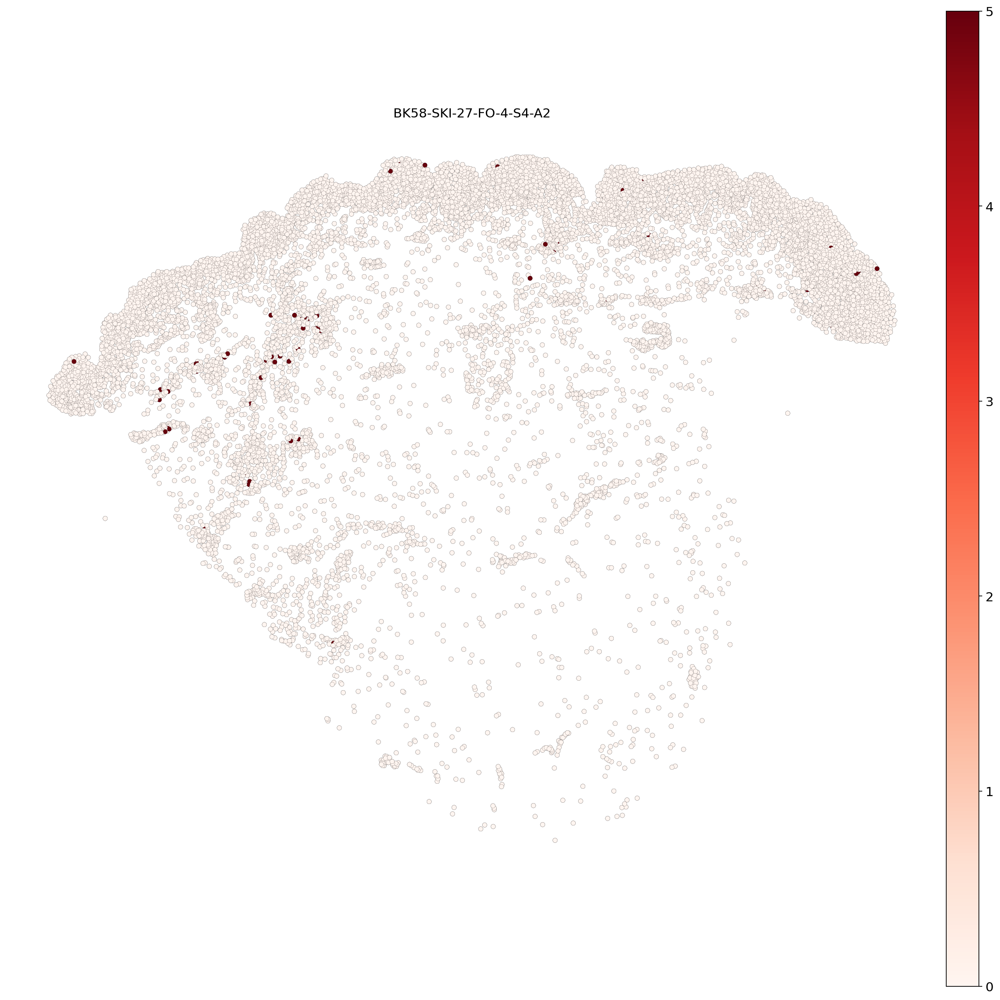

In [31]:

# # COLOR = {
# #     'Dermis': '#D8C59A',
# #     'Superficial': '#F87A7B'
# # }
# # color_palette = ListedColormap([COLOR[k] for k in COLOR.keys()])
# for x in adata[adata.obs["Mapping status"]=="revision"].obs["sample_id"].unique():
#     if "BK58" in x:
#         adata_ii = adata[adata.obs["sample_id"] == x]
#         #if x == "BK22":
#         print(x)
#         sq.pl.spatial_scatter(
#             adata_ii,
#             library_id="spatial",
#             shape=None,
#             color='CD8A',  
#             size=100,
#             edgecolor="black",
#             linewidth=0.1,
#             title=x,
#             vmax=5,
#             cmap="Reds",
#             save=f"{x}_CD8_UMAP_ALLCELLS.pdf"
#                # save = "umap_tcells_spatialdomain_forhande.pdf"

#             #palette=color_palette  
#         )

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


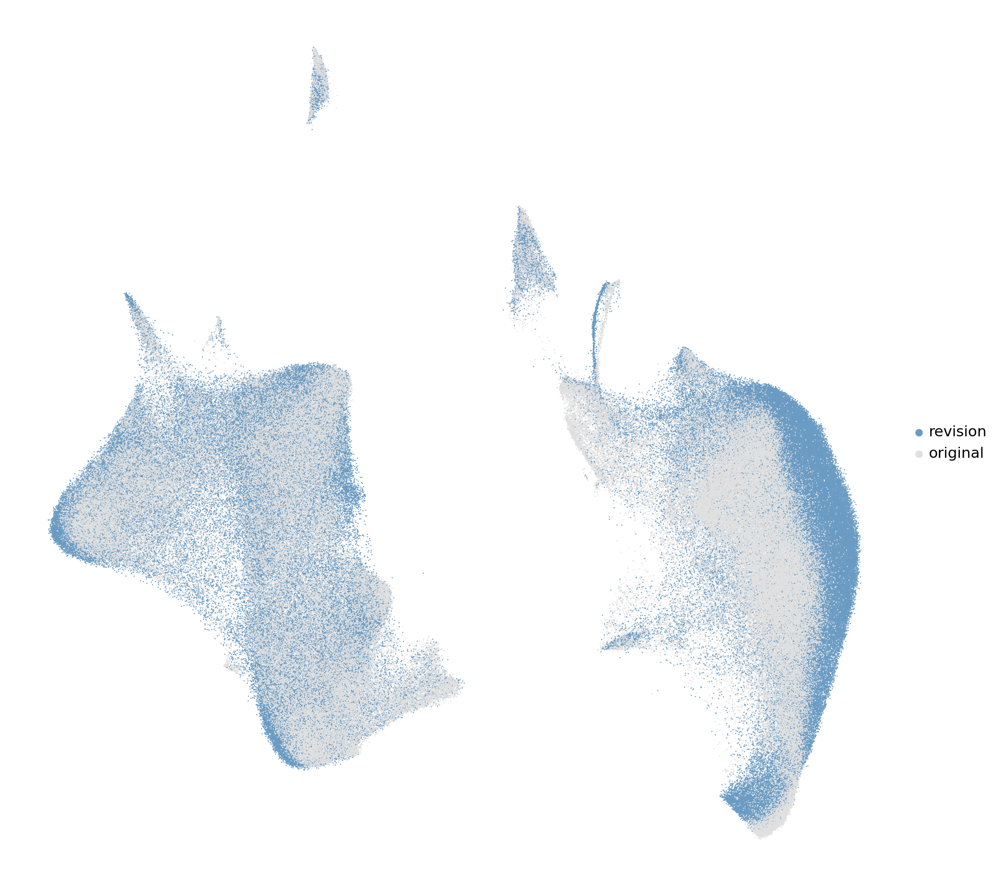

In [32]:
 
sc.pl.umap(
    adata,
    color=['Mapping status'],
    na_color='#FF4500',  # neon orange-red for NaN values
    s=5,
   # legend_loc="on data",
    legend_fontsize=14,
    legend_fontoutline=2,
    title="",
    save="validation_umap_V2.pdf",
               palette={'original': '#E0E0E0', 'revision': '#6A9BC3'},

             #  palette={'original': '#E0E0E0', 'revision': '#FF4500'},

    #linewidth=0.001,
    #edgecolor="black",
)

In [33]:
# RES=1
# sc.tl.leiden(adata, #restrict_to=(CATEGORY,subset_cluster), 
#                  resolution=RES, random_state=1, key_added=f'leiden_res{RES}') #neighbors_key='neighbor_30')

1

1

In [34]:
# sc.pl.umap(
#     adata,
#     color=[f'leiden_res{RES}'],
#     na_color='#FF4500',  # neon orange-red for NaN values
#     s=5,
#    # legend_loc="on data",
#     legend_fontsize=14,
#     legend_fontoutline=2,
#     title="",
#     #linewidth=0.001,
#     #edgecolor="black",
# )

In [35]:
genes = [
    'CD3E', 'CXCR4', 'CYBA', 'CD4', 'CCR4', 'ITGB2', 'ADAM8',
    'TNFRSF1B', 'PLEC', 'JAK3', 'IL2RG', 'FSCN1', 'CD5', 'SELPLG',
    'ACAP1', 'ITGAL', 'IKZF1', 'CD247', 'CD83', 'CCL22', 'CCR7',
    'CCL17', 'MYH9', 'RUNX3', 'CFLAR', 'BATF', 'ZAP70', 'LAMP3',
    'ALOX15', 'UCP2', 'FOXP3', 'SEPTIN9', 'CCL19', 'GRK2', 'MIAT',
    'CD6', 'TNFRSF18', 'IKZF3', 'TCF7', 'PIM2', 'IL21R', 'CTLA4',
    'CD7', 'MSN', 'SLC2A3', 'TRAF1', 'RFTN1', 'FURIN', 'SH2D2A',
    'SERPINB9'
]



In [36]:
# # For each leiden cluster, find the most common spatial_niche
# cluster_col = f'leiden_res{RES}'
# niche_col = 'spatial_niche'

# mapping = (
#     adata.obs
#     .groupby(cluster_col)[niche_col]
#     .agg(lambda x: x.value_counts().idxmax())
#     .to_dict()
# )

# adata.obs['spatial_niche2'] = adata.obs[cluster_col].map(mapping)
# adata.obs['spatial_niche2']=adata.obs['spatial_niche2'].astype('category')
# adata.uns['spatial_niche2_colors'] = [COLORS[cat] for cat in adata.obs['spatial_niche2'].cat.categories]

# sc.pl.umap(
#     adata,
#     color=['spatial_niche2'],
#     na_color='#FF4500',  
#     s=5,
#     legend_fontsize=14,
#     legend_fontoutline=2,
#     title="",
# )


In [37]:
adata.obs['Mapping status'].value_counts()

Mapping status
revision    203397
original    197483
Name: count, dtype: int64

In [38]:
adata[adata.obs["Mapping status"]!="revision"].obs.sample_id.value_counts()

sample_id
output-XETG00155__0043607__BK30-SKI-28-FO-1-S3-4__20241010__133127                            30861
output-XETG00272__0041416__BK23-SKI-27-FO-1-S6-C2__20241107__113553                           25625
output-XETG00272__0041416__BK22-SKI-27-FO-1-S10-A1__20241107__113553                          21656
output-XETG00272__0041416__BK23-SKI-27-FO-2-S6-D1_BK23-SKI-27-FO-4-S6-E1__20241107__113553    18244
output-XETG00272__0027131__Region_7__20240628__124459                                         17792
output-XETG00155__0043607__BK30-SKI-27-FO-1-2-S3__20241010__133127                            17378
output-XETG00155__0043607__BK39-SKI-27-FO-2-S3-4__20241010__133127                            17005
output-XETG00155__0043607__BK39-SKI-27-FO-1-S3__20241010__133127                              16836
output-XETG00272__0027175__Region_2__20240628__124459                                         16555
output-XETG00272__0027175__Region_7__20240628__124459                                     

In [39]:
adata[adata.obs["Mapping status"]=="revision"].obs.sample_id.value_counts()

sample_id
BK44-SKI-27-FO-1-S4-E2    30151
BK40-SKI-27-FO-1-S4-D2    29527
BK68-SKI-27-FO-1-S4-B2    24602
BK65-SKI-21-FO-1-S4-B1    19762
BK36-SKI-27-FO-1-S4-D1    19285
BK42-SKI-27-FO-1-S4-C2    19273
BK36-SKI-27-FO-1-S5-E1    18809
BK37-SKI-27-FO-1-S4-C1    14787
BK58-SKI-27-FO-1-S5-A1    14011
BK58-SKI-27-FO-4-S4-A2    13190
Name: count, dtype: int64

In [40]:
{x:x for x in sorted(adata[adata.obs["Mapping status"]=="revision"].obs["sample_id"].unique())}

{'BK36-SKI-27-FO-1-S4-D1': 'BK36-SKI-27-FO-1-S4-D1',
 'BK36-SKI-27-FO-1-S5-E1': 'BK36-SKI-27-FO-1-S5-E1',
 'BK37-SKI-27-FO-1-S4-C1': 'BK37-SKI-27-FO-1-S4-C1',
 'BK40-SKI-27-FO-1-S4-D2': 'BK40-SKI-27-FO-1-S4-D2',
 'BK42-SKI-27-FO-1-S4-C2': 'BK42-SKI-27-FO-1-S4-C2',
 'BK44-SKI-27-FO-1-S4-E2': 'BK44-SKI-27-FO-1-S4-E2',
 'BK58-SKI-27-FO-1-S5-A1': 'BK58-SKI-27-FO-1-S5-A1',
 'BK58-SKI-27-FO-4-S4-A2': 'BK58-SKI-27-FO-4-S4-A2',
 'BK65-SKI-21-FO-1-S4-B1': 'BK65-SKI-21-FO-1-S4-B1',
 'BK68-SKI-27-FO-1-S4-B2': 'BK68-SKI-27-FO-1-S4-B2'}

In [41]:
RENAME={'BK36-SKI-27-FO-1-S4-D1': 'M',
 'BK36-SKI-27-FO-1-S5-E1': 'M',
 'BK37-SKI-27-FO-1-S4-C1': 'M',
 'BK40-SKI-27-FO-1-S4-D2': 'M',
 'BK42-SKI-27-FO-1-S4-C2': 'F',
 'BK44-SKI-27-FO-1-S4-E2': 'F',
 'BK58-SKI-27-FO-1-S5-A1': 'F',
 'BK58-SKI-27-FO-4-S4-A2': 'F',
 'BK65-SKI-21-FO-1-S4-B1': 'F',
 'BK68-SKI-27-FO-1-S4-B2': 'M'}

In [42]:
RENAME={'BK36': '18-30, White M',
 'BK37': '18-30, Asian or Asian British M',
 'BK40': '18-30, Mixed Background M',
 'BK42': '30-40, White F',
 'BK44': '18-30, Asian or Asian British F',
 'BK58': '40-50, White F',
 'BK65': '18-30, White F',
 'BK68': '40-50, White M'}

In [43]:
adata[adata.obs["Mapping status"]=="revision"].obs["Sanger patient ID"].value_counts()

Sanger patient ID
BK36    38094
BK44    30151
BK40    29527
BK58    27201
BK68    24602
BK65    19762
BK42    19273
BK37    14787
Name: count, dtype: int64

In [44]:
adata[adata.obs["Mapping status"]=="revision"].obs["sample_id"].value_counts()

sample_id
BK44-SKI-27-FO-1-S4-E2    30151
BK40-SKI-27-FO-1-S4-D2    29527
BK68-SKI-27-FO-1-S4-B2    24602
BK65-SKI-21-FO-1-S4-B1    19762
BK36-SKI-27-FO-1-S4-D1    19285
BK42-SKI-27-FO-1-S4-C2    19273
BK36-SKI-27-FO-1-S5-E1    18809
BK37-SKI-27-FO-1-S4-C1    14787
BK58-SKI-27-FO-1-S5-A1    14011
BK58-SKI-27-FO-4-S4-A2    13190
Name: count, dtype: int64

In [45]:
adata[adata.obs["Mapping status"]=="revision"].obs["Sanger patient ID"].nunique()

8

# extended 10b

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


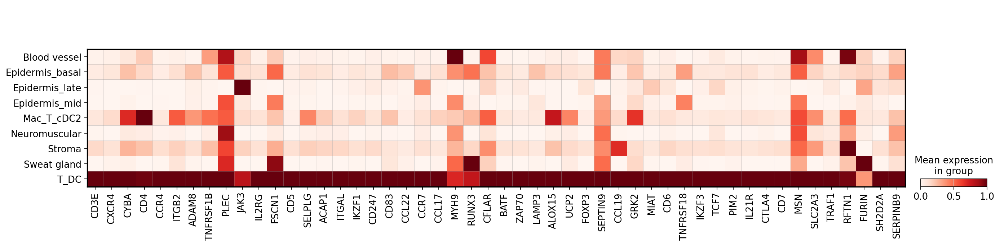

In [47]:
sc.pl.matrixplot(adata[adata.obs["Mapping status"]=="revision"], 
              genes,
              groupby=f'spatial_niche2',
              dendrogram=False, 
                standard_scale="var",
             #dot_max=0.3,
                 cmap="Reds",    
                 save="validation_TDC_MGP.pdf"

             )

In [48]:
0

0

In [49]:
# PATH='/nfs/team361/ls34/inflow/adata_10ad_spatial_validation.h5ad'
# adata.write(PATH)

In [50]:
# STOP

In [51]:
# adata.obs.broad_celltypes.value_counts()

In [52]:
# adata.obs.broad_annotations.value_counts()

In [53]:
# adata.obs.broad_annotations.isna().sum()

In [54]:
# adata_i = adata[adata.obs["broad_annotations"].str.startswith("T")].copy()

In [55]:
if DATA_PREPARED_T:
    adata_i=sc.read_h5ad('/nfs/team361/ls34/inflow/adata_10ad_spatial_validation_tcell.h5ad')

if not DATA_PREPARED_T:
    adata_i = adata[adata.obs["broad_annotations"].str.startswith("T")].copy()
    sc.pp.neighbors(adata_i, use_rep = M_BAR_METRIC, 
                    metric = "euclidean", n_neighbors=20)#key_added=neighbor_id)
    sc.tl.umap(adata_i, min_dist=0.1) #neighbor_key=)


    sc.pl.umap(adata_i,  
               color=[ "NICHE_NAMES", key_celltype],
               s=200,legend_loc="on data",
               legend_fontsize=8)

    RES=0.1
    sc.tl.leiden(adata_i, #restrict_to=(CATEGORY,subset_cluster), 
                 resolution=RES, random_state=1, key_added=f'leiden_res{RES}') 


    sc.pl.umap(adata_i,  
               color=[ key_celltype, f"leiden_res{RES}"],
               s=200,legend_loc="on data",
               legend_fontsize=8
              )

else:
    print("skip as data prepared")

skip as data prepared


In [56]:
# adata_i.write('/nfs/team361/ls34/inflow/adata_10ad_spatial_validation_tcell.h5ad')

In [57]:
# #adata=sc.read_h5ad('/nfs/team361/ls34/inflow/adata_10ad_spatial_validation2.h5ad')

# RECODE = {'original': 'revision',
#           'revision': 'original'


# }
# adata_i.obs["Mapping status"]=adata_i.obs["Mapping status"].map(RECODE)
# adata_i.obs["Mapping status"].value_counts()

In [58]:
# STIPP

In [59]:

# print("load prepped data")
# adata_t_original =sc.read_h5ad('/nfs/team361/ls34/inflow/final_adatas/adata_tcells.h5ad')
# COLOR = {
#     'Dermis': '#EFE8D7',
#     'Superficial': '#F87A7B'
# }
# adata_t_original.obs["t_cellsubtypes"] =adata_t_original.obs["t_cellsubtypes"].astype('category')
# adata_t_original.uns["t_cellsubtypes_colors"] = [COLOR[subtype] for subtype in adata_t_original.obs['t_cellsubtypes'].cat.categories]

# #adata_i.shape

In [60]:
# md = adata_t_original.obs["t_cellsubtypes"].to_dict()
# adata_i.obs["t_cellsubtypes"] = adata_i.obs.index.map(md)



In [61]:
# sc.pl.umap(adata_i,  
#                color=[ "t_cellsubtypes"],
#                s=50,legend_loc="on data",
#                legend_fontsize=8,
#             palette = {
#     'Dermis': '#EFE8D7',
#     'Superficial': '#F87A7B',},
#                na_color='#FF4500',  # neon orange-red for NaN values

#               )

# sc.pl.umap(adata_i,  
#                color=[ "t_cellsubtypes"],
#                s=50,legend_loc="on data",
#                legend_fontsize=8,
#             palette = {
#     'Dermis': '#EFE8D7',
#     'Superficial': '#F87A7B',},
#                na_color='#FF4500',  # neon orange-red for NaN values
#            linewidth=0.01,
#            edgecolor='black',

#               )

In [62]:
# RES=0.3
# sc.tl.leiden(adata_i, #restrict_to=(CATEGORY,subset_cluster), 
#                  resolution=RES, random_state=1, key_added=f'leiden_res{RES}') 


In [63]:
# sc.pl.umap(adata_i,  
#                color=[ "leiden_res0.3"],
#                s=50,legend_loc="on data",
#                legend_fontsize=8
#               )

In [64]:
# RENAME = {"2": "Superficial",
#           "0": "Dermis",
#           "1": "Dermis",
#          }
# adata_i.obs["tcell_all"] = adata_i.obs["leiden_res0.3"].map(RENAME)

# fig 4l

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


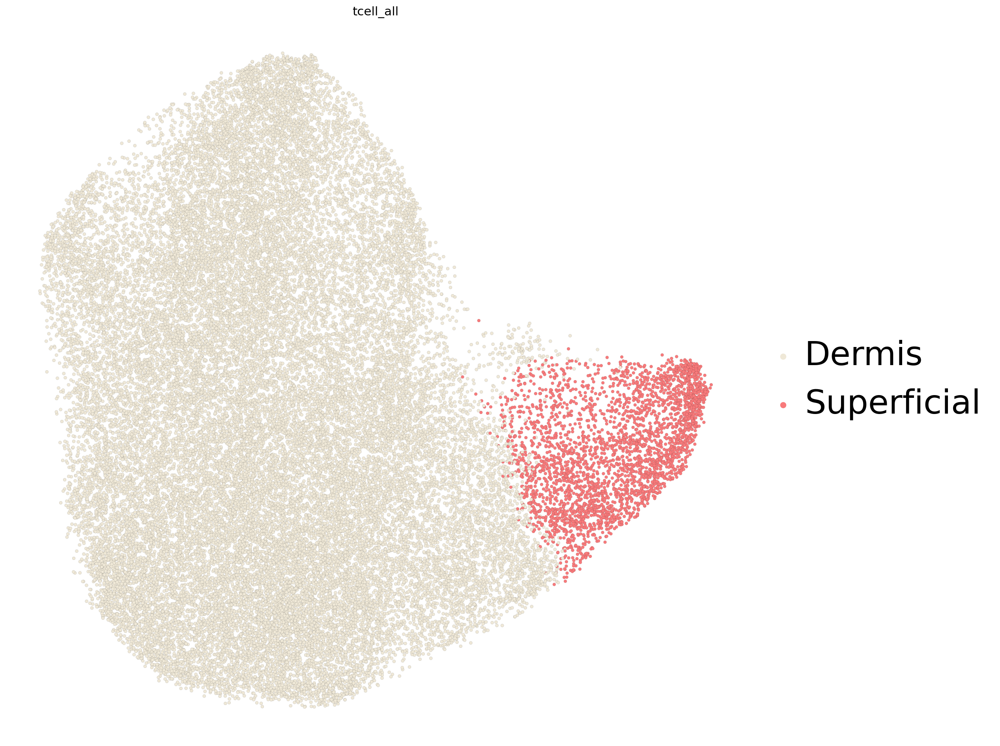

In [65]:
#sc.settings.set_figure_params(dpi=50, dpi_save=300, facecolor="white", frameon=False, figsize=(12, 12))
# if not DATA_PREPARED_T:

#     RENAME  = {'0': "Dermis",
#                '1': "Dermis",
#                '2': "Superficial" 
#               }

#     adata_i.obs["t_cellsubtypes"] =adata_i.obs[ f"leiden_res{RES}"].map(RENAME)#.fillna(adata_i.obs[ f"leiden_res{RES}"])
#     sc.pl.umap(adata_i,  
#                color=["t_cellsubtypes"],
#                s=200,legend_loc="on data",
#                legend_fontsize=8
#               )

#     # in this plot, how can i colour:
#     #        'Dermis': '#8C6A3B',
#     #     'Superficial': '#F87A7B',


# sc.pl.umap(
#     adata_i,  
#     color=["t_cellsubtypes"],
#     s=200,
#     legend_loc="on data",
#     legend_fontsize=40,
#     legend_fontoutline=2,
#                 edgecolor="black",
#             linewidth=0.1,
#     save = "umap_tcells_spatialdomain.pdf"
# )


sc.pl.umap(adata_i,  
               color=[ "tcell_all"],
               s=50,
           #legend_loc="on data",
               legend_fontsize=38,
                           edgecolor="black",
            linewidth=0.05,
                palette = {
    'Dermis': '#EFE8D7',
    'Superficial': '#F87A7B',},
                      save="VALIDATION_TCELL_SPATIAL_v2.pdf"
                    
              )

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


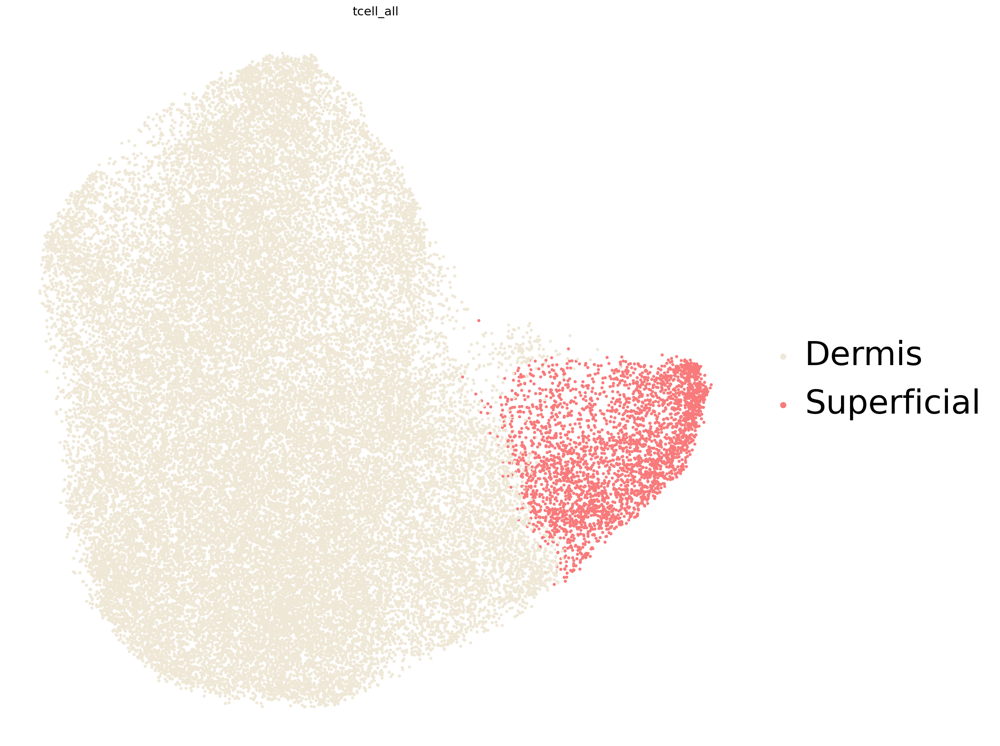

In [66]:
sc.pl.umap(adata_i,  
               color=[ "tcell_all"],
               s=50,
           #legend_loc="on data",
               legend_fontsize=38,
                palette = {
    'Dermis': '#EFE8D7',
    'Superficial': '#F87A7B',},
                      save="VALIDATION_TCELL_SPATIAL_v2.pdf"
                    
              )

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


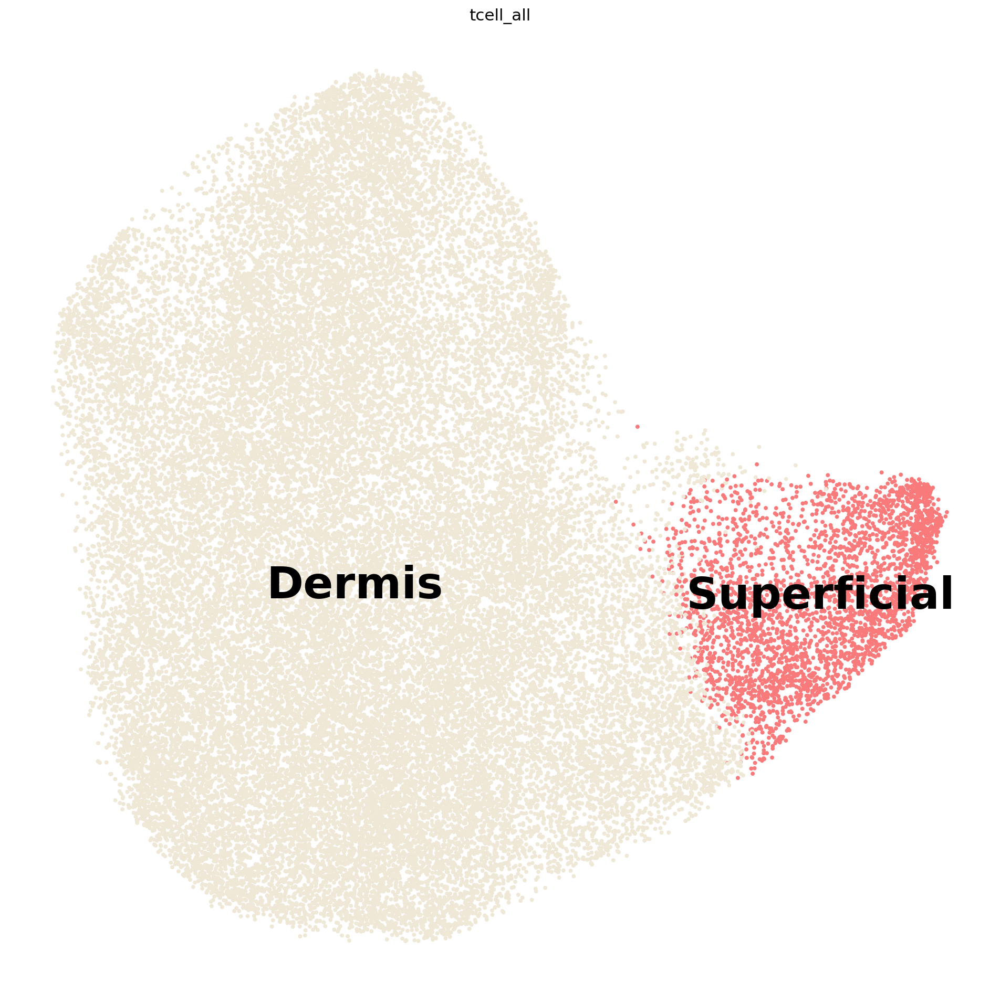

In [67]:
sc.pl.umap(adata_i,  
               color=[ "tcell_all"],
               s=50,legend_loc="on data",
               legend_fontsize=38,
                palette = {
    'Dermis': '#EFE8D7',
    'Superficial': '#F87A7B',},
                      save="VALIDATION_TCELL_SPATIAL.pdf"
                    
              )

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


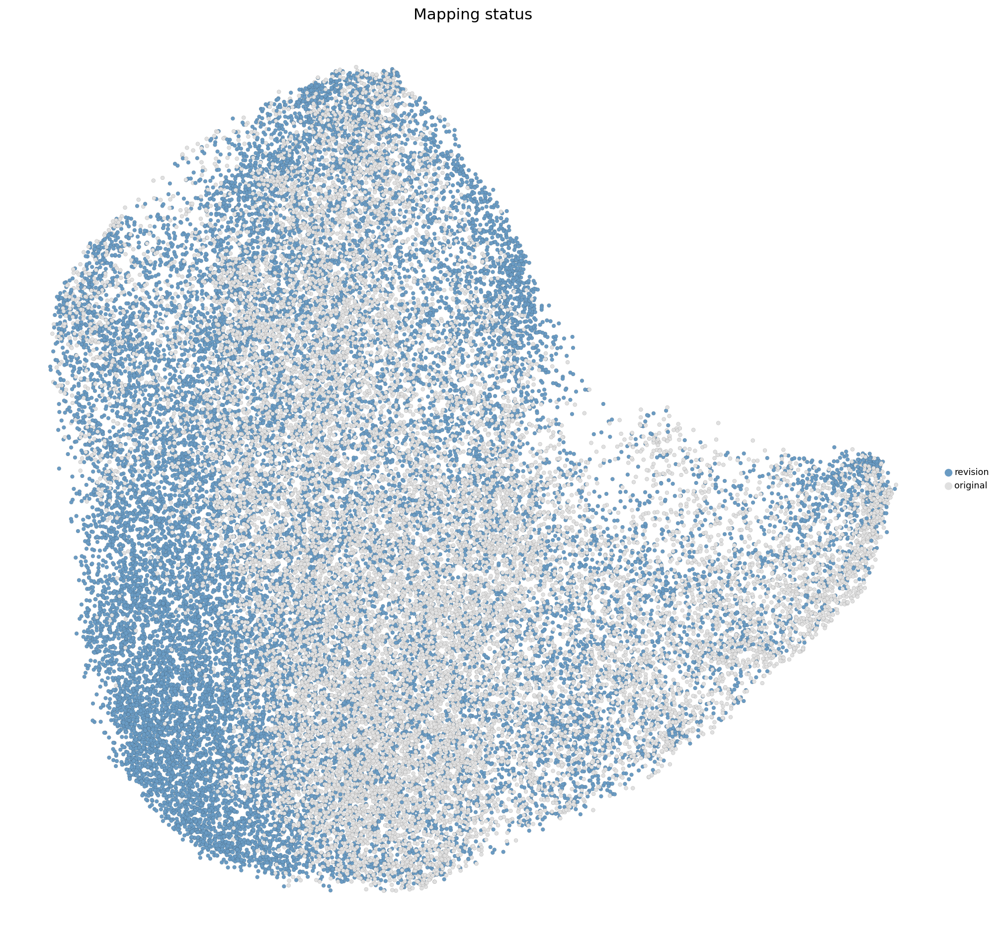

In [70]:
sc.pl.umap(adata_i,
           color=["Mapping status"],
           s=50,
           legend_fontsize=8,
           palette={'original': '#E0E0E0', 'revision': '#6A9BC3'},
                 edgecolor="black",
            linewidth=0.05,
           save="Tcells_Mapping_validation.pdf"
)

In [71]:
adata_i.obs["Mapping status"].value_counts()

Mapping status
revision    22327
original    17064
Name: count, dtype: int64

In [72]:
adata_i[adata_i.obs["Mapping status"]=="revision"].obs["sample_id"].value_counts()

sample_id
BK44-SKI-27-FO-1-S4-E2    8301
BK40-SKI-27-FO-1-S4-D2    4541
BK65-SKI-21-FO-1-S4-B1    1592
BK58-SKI-27-FO-1-S5-A1    1560
BK42-SKI-27-FO-1-S4-C2    1480
BK36-SKI-27-FO-1-S5-E1    1125
BK36-SKI-27-FO-1-S4-D1    1082
BK68-SKI-27-FO-1-S4-B2    1024
BK37-SKI-27-FO-1-S4-C1     949
BK58-SKI-27-FO-4-S4-A2     673
Name: count, dtype: int64

In [73]:
adata_i[adata_i.obs["Mapping status"]!="revision"].obs["sample_id"].value_counts()

sample_id
output-XETG00272__0041416__BK22-SKI-27-FO-1-S10-A1__20241107__113553                          5316
output-XETG00155__0043607__BK30-SKI-28-FO-1-S3-4__20241010__133127                            2457
output-XETG00155__0043607__BK39-SKI-27-FO-1-S3__20241010__133127                              2255
output-XETG00272__0027175__Region_7__20240628__124459                                         1344
output-XETG00272__0041416__BK23-SKI-27-FO-2-S6-D1_BK23-SKI-27-FO-4-S6-E1__20241107__113553    1313
output-XETG00155__0043607__BK39-SKI-27-FO-2-S3-4__20241010__133127                            1289
output-XETG00272__0041416__BK23-SKI-27-FO-1-S6-C2__20241107__113553                            992
output-XETG00155__0043607__BK30-SKI-27-FO-1-2-S3__20241010__133127                             880
output-XETG00272__0027131__Region_7__20240628__124459                                          845
output-XETG00272__0027175__Region_2__20240628__124459                                          373


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-package

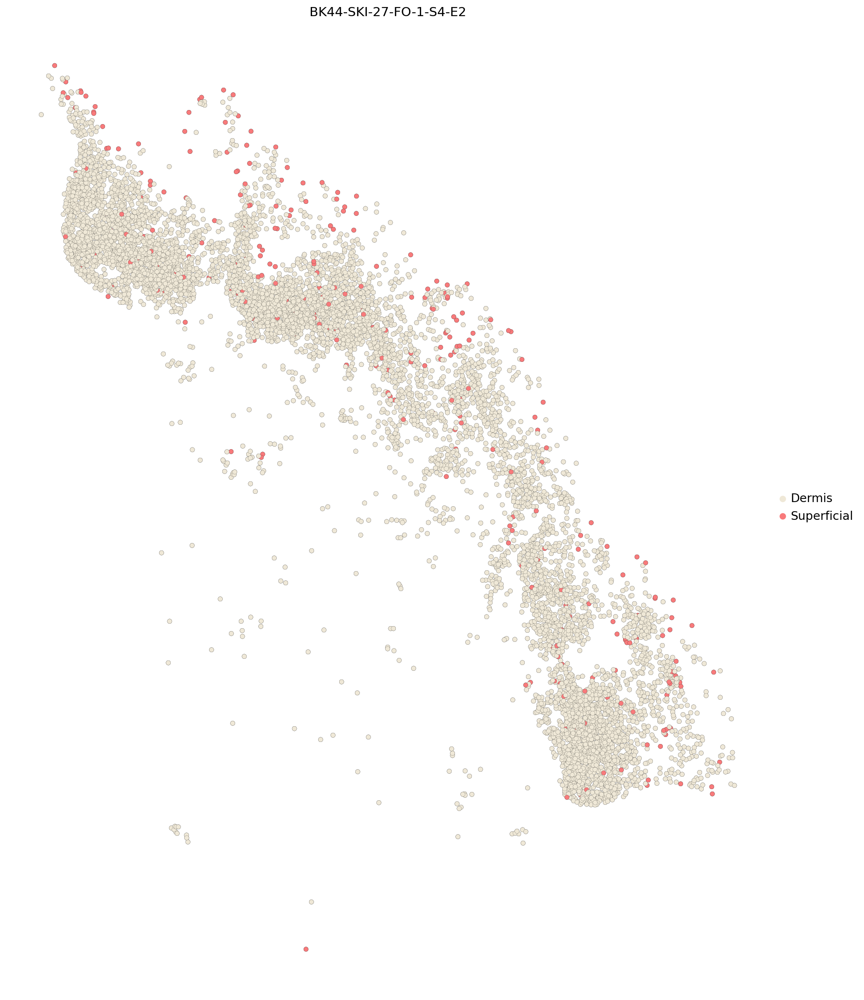

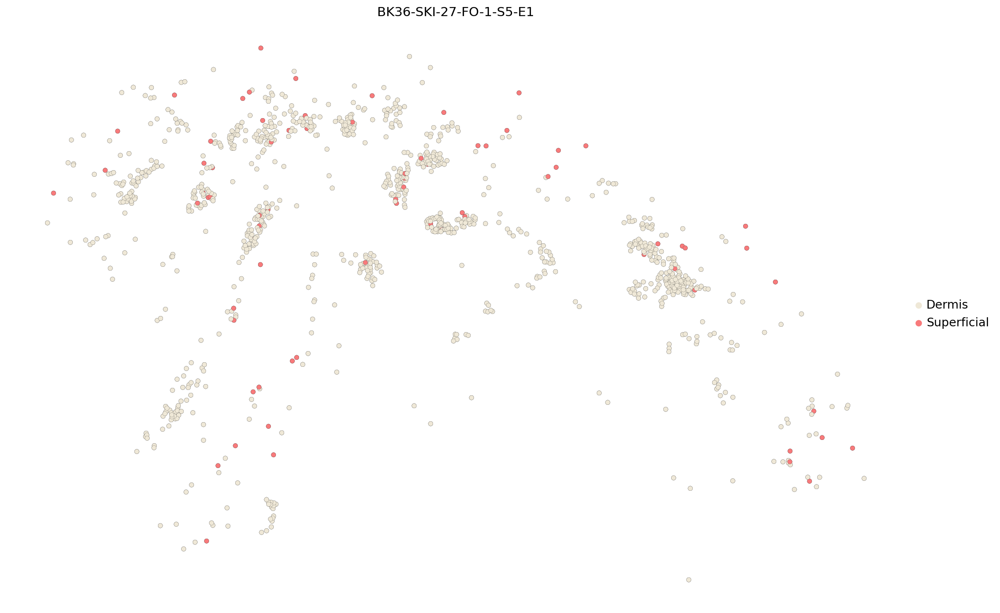

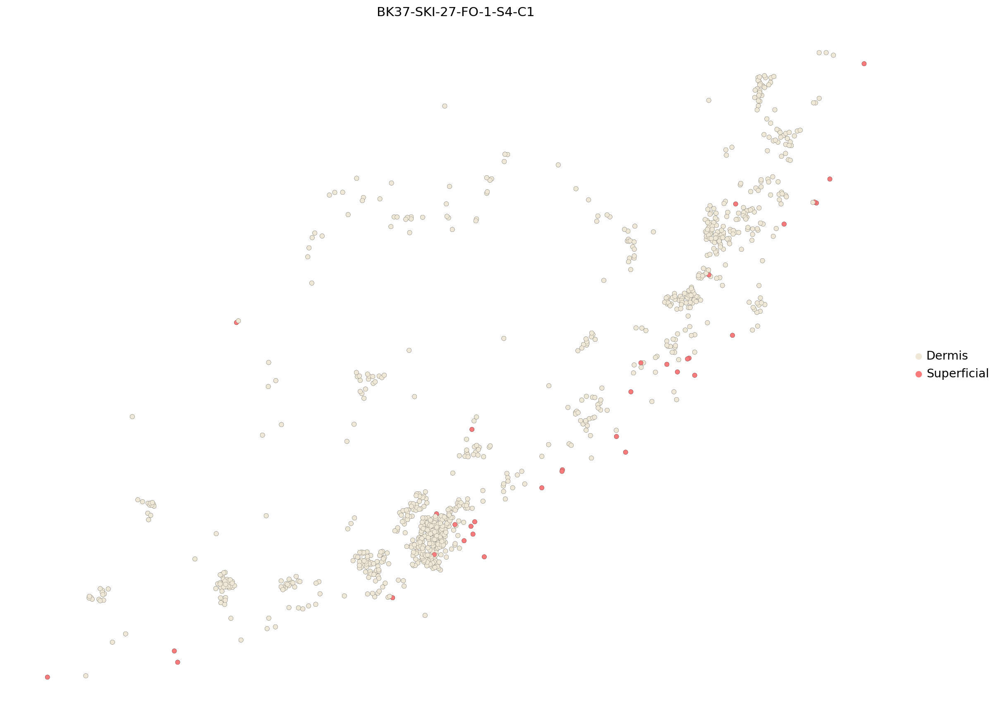

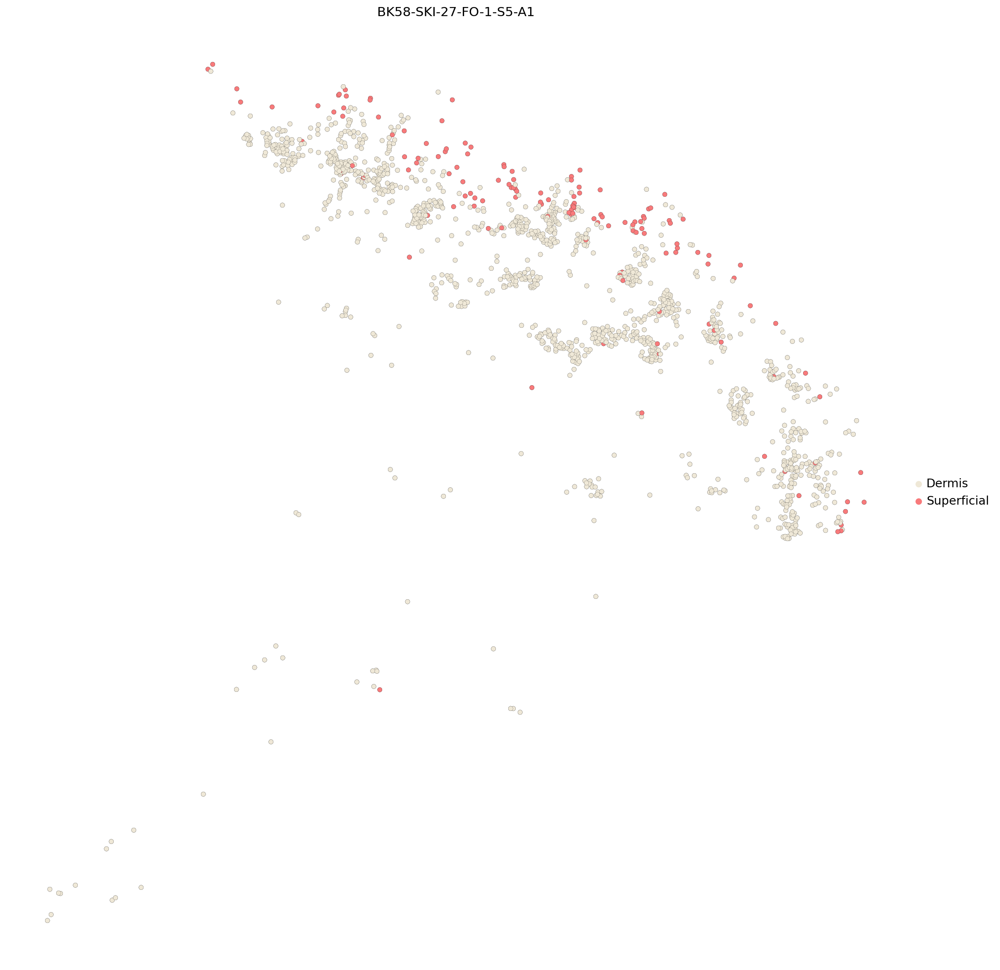

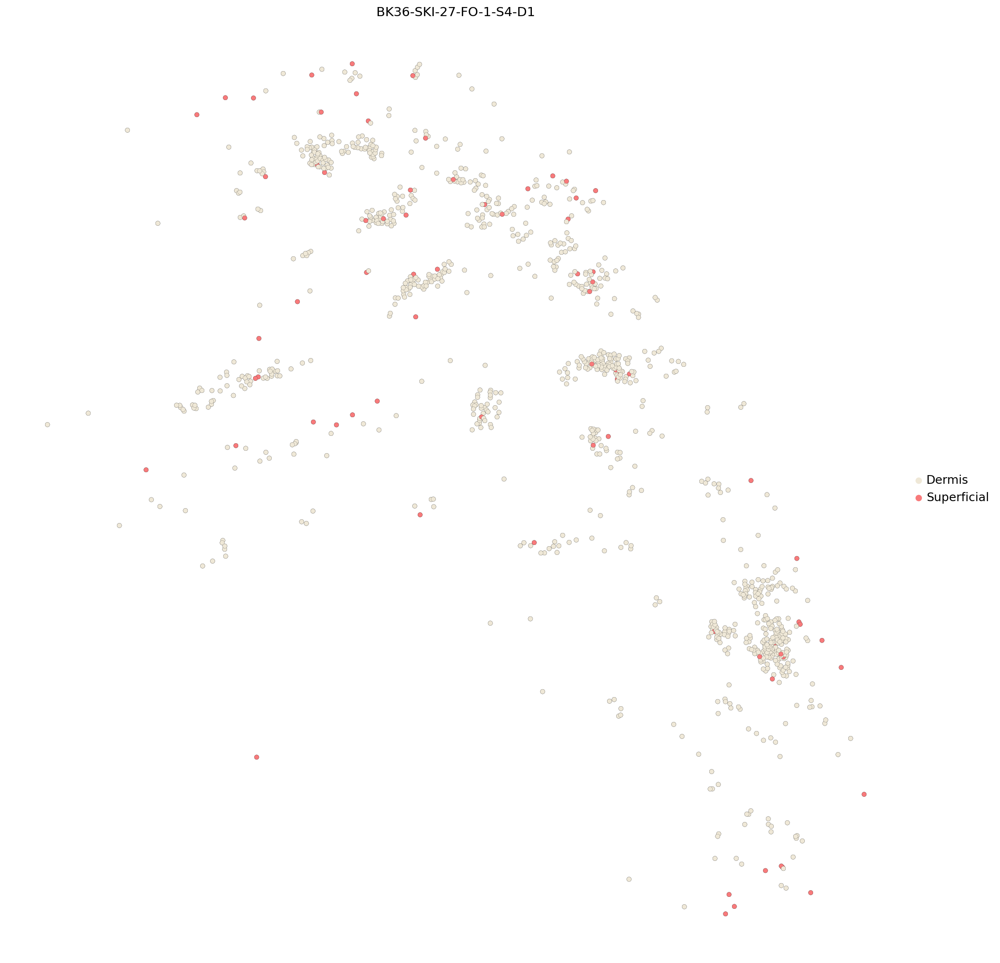

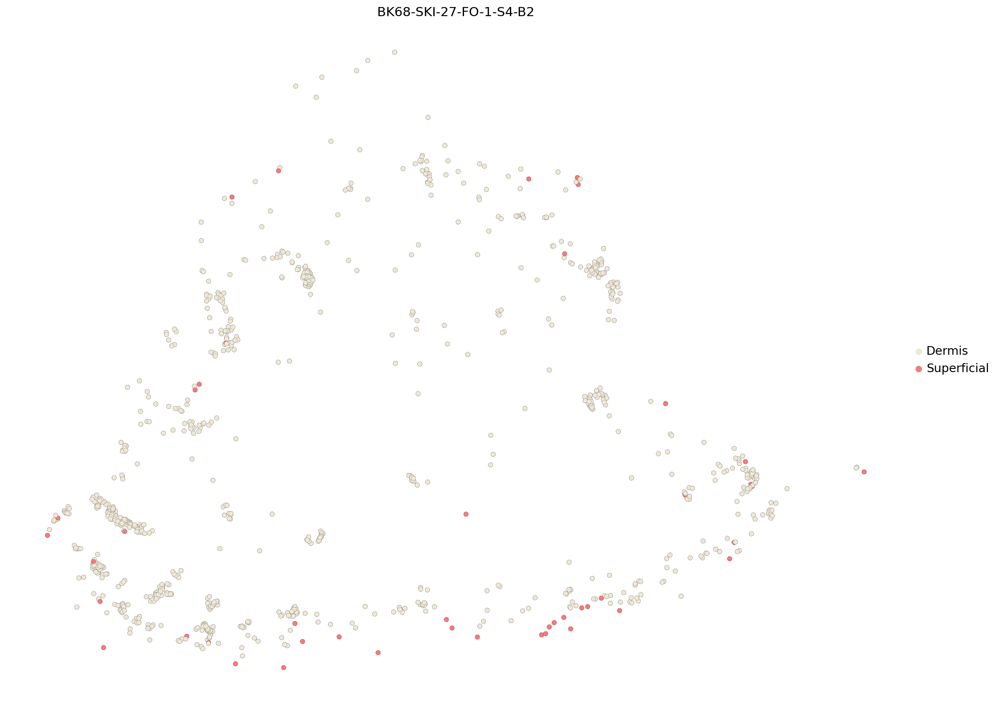

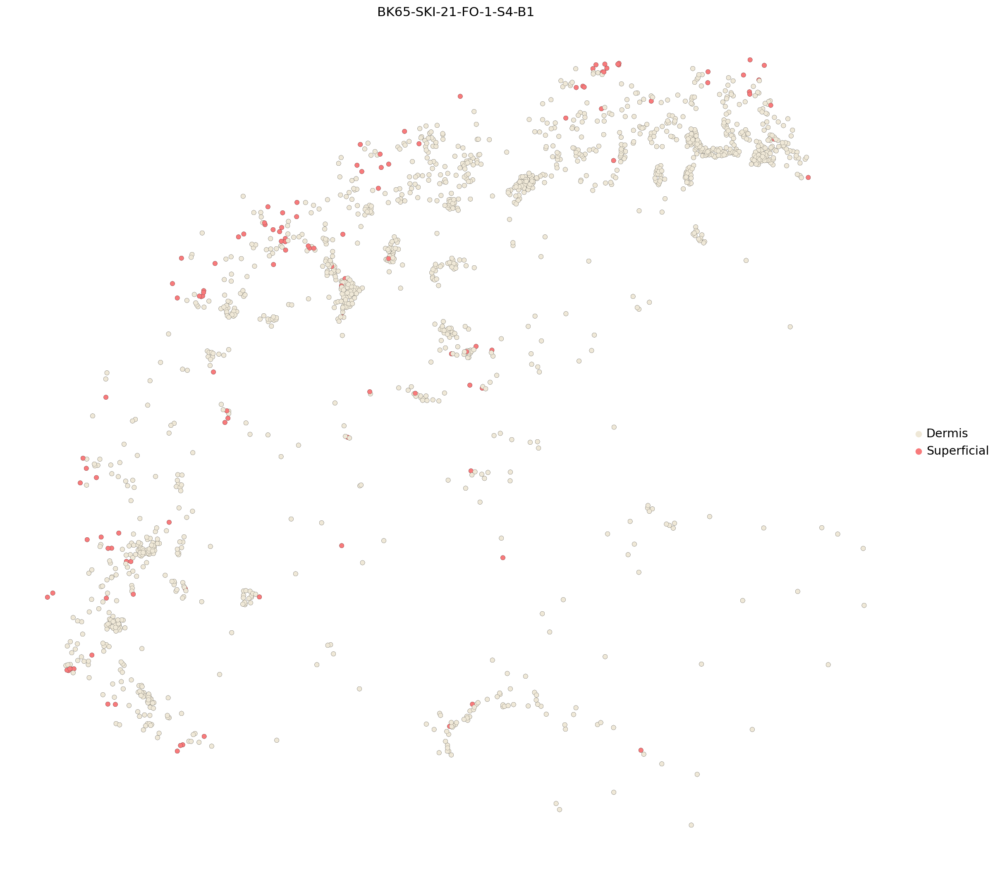

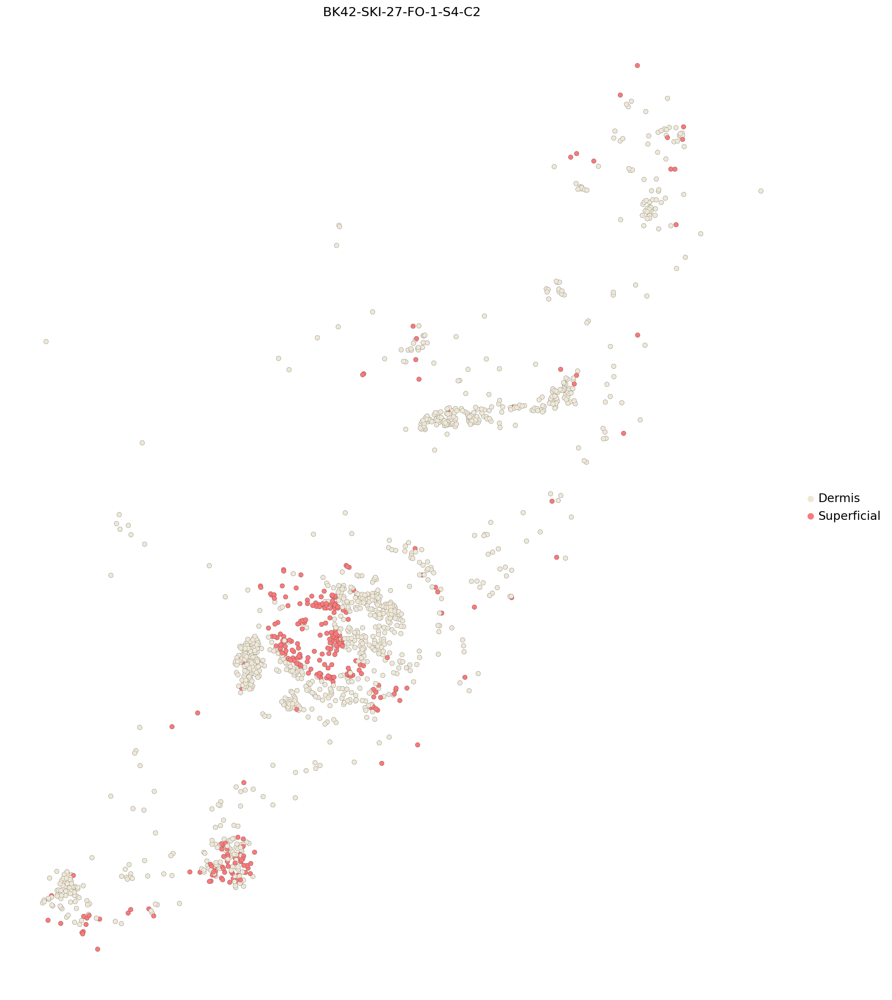

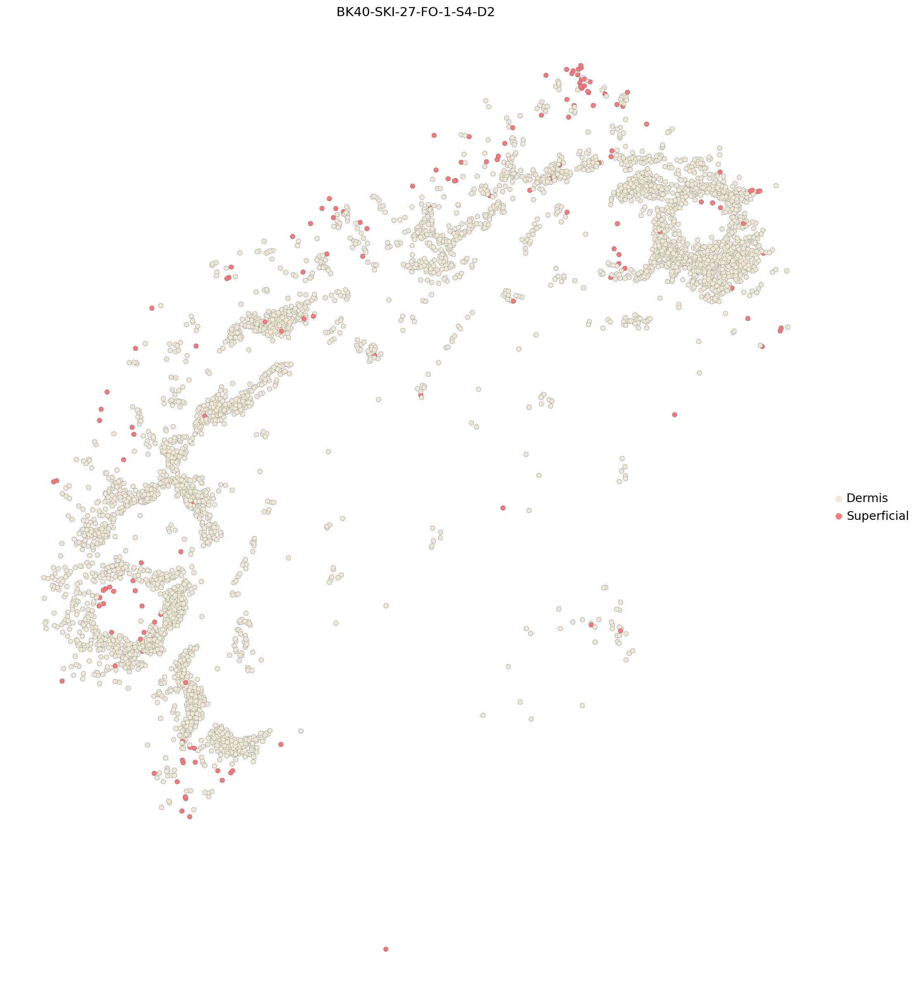

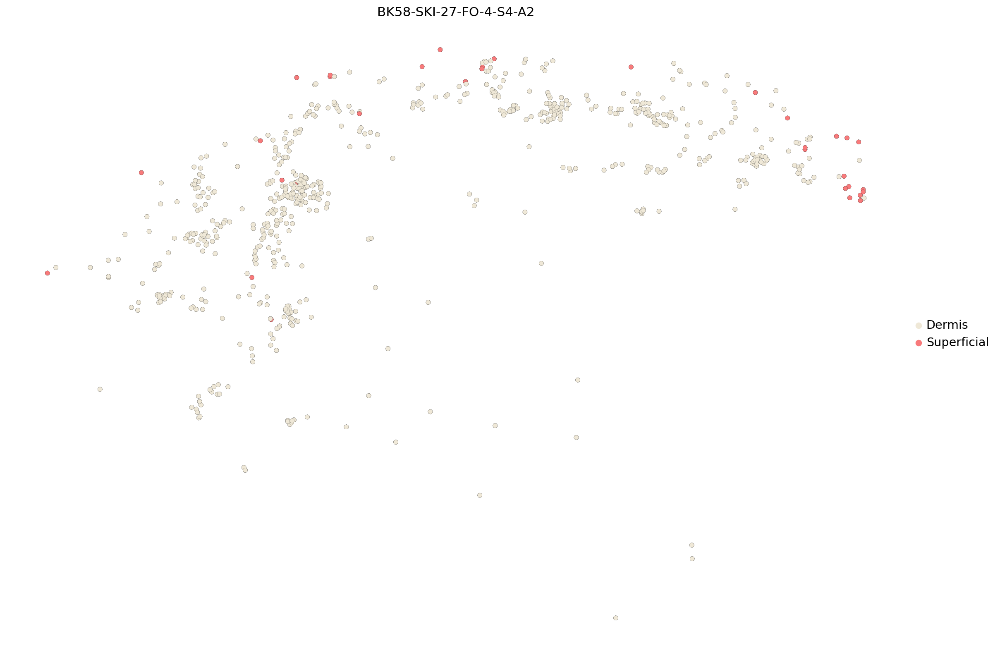

In [74]:

# COLOR = {
#     'Dermis': '#D8C59A',
#     'Superficial': '#F87A7B'
# }
# color_palette = ListedColormap([COLOR[k] for k in COLOR.keys()])
for x in adata_i[adata_i.obs["Mapping status"]=="revision"].obs["sample_id"].unique():
    adata_ii = adata_i[adata_i.obs["sample_id"] == x]
    #if x == "BK22":
    sq.pl.spatial_scatter(
        adata_ii,
        library_id="spatial",
        shape=None,
        color='tcell_all',  
        size=100,
        edgecolor="black",
        linewidth=0.1,
        title=x,
        save=f"{x}_UMAP.pdf"
           # save = "umap_tcells_spatialdomain_forhande.pdf"

        #palette=color_palette  
    )

# figure 4l , extended 10c

BK58-SKI-27-FO-1-S5-A1
BK58-SKI-27-FO-4-S4-A2


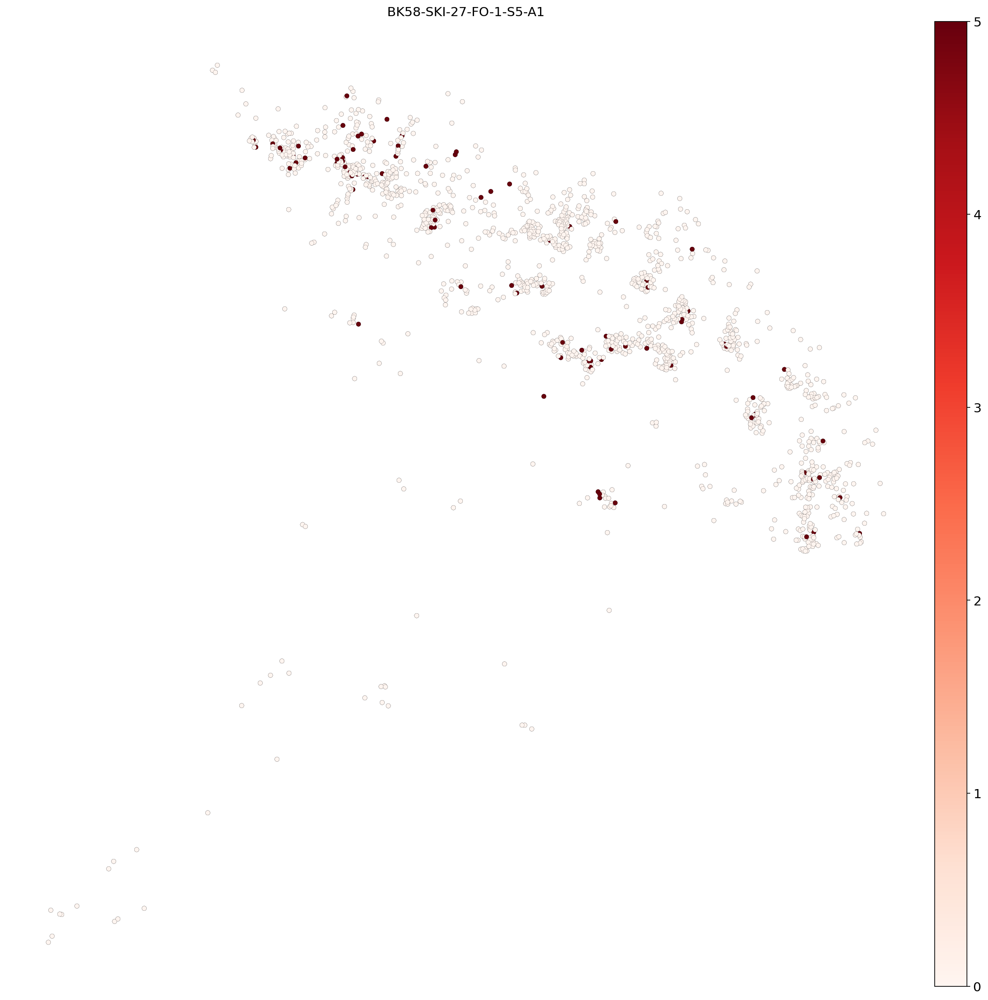

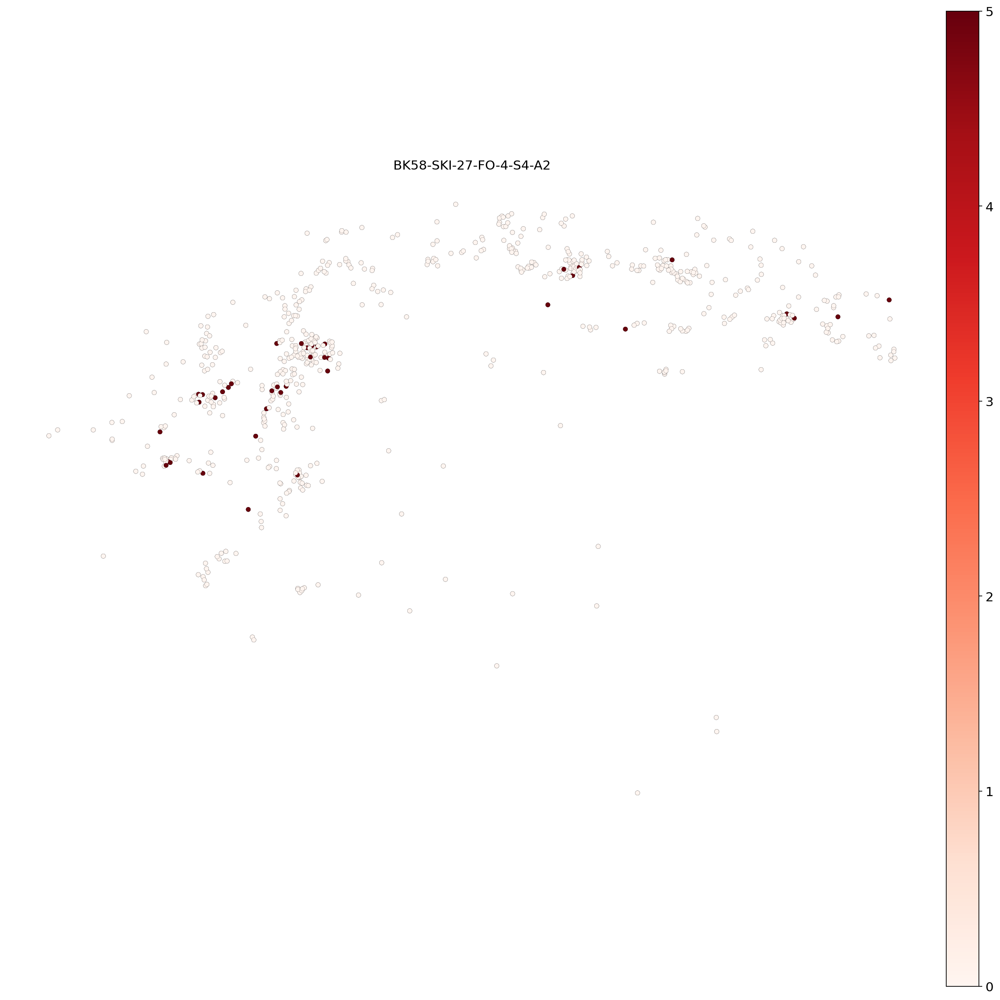

In [75]:

# COLOR = {
#     'Dermis': '#D8C59A',
#     'Superficial': '#F87A7B'
# }
# color_palette = ListedColormap([COLOR[k] for k in COLOR.keys()])
for x in adata_i[adata_i.obs["Mapping status"]=="revision"].obs["sample_id"].unique():
    if "BK58" in x:
        adata_ii = adata_i[adata_i.obs["sample_id"] == x]
        #if x == "BK22":
        print(x)
        sq.pl.spatial_scatter(
            adata_ii,
            library_id="spatial",
            shape=None,
            color='CD8A',  
            size=100,
            edgecolor="black",
            linewidth=0.1,
            title=x,
            vmax=5,
            cmap="Reds",
            save=f"{x}_CD8_UMAP.pdf"
               # save = "umap_tcells_spatialdomain_forhande.pdf"

            #palette=color_palette  
        )